# EfficientNet-B0 en Google Colab — PlantVillage

Notebook autocontenido para entrenar un clasificador multiclase con transfer learning usando EfficientNet-B0 preentrenado en ImageNet. Está basado en la línea base de MobileNetV2 del proyecto `LeaftHealthVision`, pero no depende de módulos locales del repositorio.

**Runtime recomendado:** GPU (`Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU`).

> Importante: EfficientNet de Keras ya incorpora el preprocesamiento como una capa `Rescaling`. Por ello, las imágenes se entregan al modelo como tensores float con valores `[0, 255]`; no se aplica `1/255` antes de la base convolucional.


In [1]:
# 0. Dependencias
!pip -q install -U tensorflow matplotlib scikit-learn mlflow codecarbon


In [2]:
# 1. Imports, reproducibilidad y configuración editable
import os
import random
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import applications, layers
from tensorflow.keras.models import Model

SEED = 42
BATCH_SIZE = 32
IMAGE_TARGET_SIZE = (224, 224)
TRAIN_SPLIT = 0.80
VAL_SPLIT = 0.10
TEST_SPLIT = 0.10
EPOCHS = 10
EARLY_STOPPING_PATIENCE = 5
LEARNING_RATE = 1e-3
USE_DATA_AUGMENTATION = True
RUN_FINE_TUNING = False
FINE_TUNE_EPOCHS = 5
FINE_TUNE_LEARNING_RATE = 1e-5
FINE_TUNE_LAST_N_LAYERS = 20

WORK = Path('/content/leafthealthvision')
DATA_DIR = WORK / 'data' / 'plantvillage'
COLOR_DIR = DATA_DIR / 'raw' / 'color'
MODEL_DIR = WORK / 'artifacts'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPO_URL = 'https://github.com/spMohanty/PlantVillage-Dataset.git'

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        tf.keras.mixed_precision.set_global_policy('mixed_float16')
        print(f'GPU activada: {len(gpus)} dispositivo(s), mixed_float16')
    except RuntimeError as exc:
        print(f'Nota GPU: {exc}')
else:
    print('No se detectó GPU; se usará CPU')

print({
    'tensorflow': tf.__version__,
    'device': tf.config.list_logical_devices('GPU'),
    'image_size': IMAGE_TARGET_SIZE,
    'batch_size': BATCH_SIZE,
})


GPU activada: 1 dispositivo(s), mixed_float16
{'tensorflow': '2.21.0', 'device': [LogicalDevice(name='/device:GPU:0', device_type='GPU')], 'image_size': (224, 224), 'batch_size': 32}


In [3]:
# 2.5. MLflow: seguimiento del experimento (se guarda en ./mlruns del entorno)
import mlflow
from codecarbon import EmissionsTracker

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("leafthealthvision-efficientnetb0")


class MlflowEpochLogger(tf.keras.callbacks.Callback):
    """Registra métricas de cada época en MLflow."""

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        mlflow.log_metrics({k: float(v) for k, v in logs.items()}, step=epoch)


2026/11/17 03:21:16 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 03:21:16 INFO mlflow.store.db.utils: Updating database tables
2026/11/17 03:21:19 INFO mlflow.tracking.fluent: Experiment with name 'leafthealthvision-efficientnetb0' does not exist. Creating a new experiment.


In [4]:
# 2. Descargar PlantVillage (solo la primera vez)
if not COLOR_DIR.exists():
    WORK.mkdir(parents=True, exist_ok=True)
    print(f'Clonando {REPO_URL} ...')
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(DATA_DIR)], check=True)
    git_dir = DATA_DIR / '.git'
    if git_dir.exists():
        shutil.rmtree(git_dir)
    keep = {'raw', 'leaf_grouping', 'leaf-map.json', 'README.md', 'CITATION.cff'}
    for item in list(DATA_DIR.iterdir()):
        if item.name not in keep:
            shutil.rmtree(item) if item.is_dir() else item.unlink()
else:
    print(f'Dataset ya descargado en: {DATA_DIR}')

if not COLOR_DIR.exists():
    raise FileNotFoundError(f'No existe el directorio esperado: {COLOR_DIR}')

class_count = len([p for p in COLOR_DIR.iterdir() if p.is_dir()])
print(f'Imágenes en: {COLOR_DIR}')
print(f'Clases encontradas: {class_count}')


Clonando https://github.com/spMohanty/PlantVillage-Dataset.git ...
Imágenes en: /content/leafthealthvision/data/plantvillage/raw/color
Clases encontradas: 38


In [5]:
# 3. Cargar y dividir el dataset
# La división reproduce la línea base del notebook MobileNetV2.
# Para una evaluación académica estricta, se recomienda usar los manifiestos
# por hoja generados por el EDA del repositorio y evitar dividir duplicados
# de una misma hoja entre train/val/test.
AUTOTUNE = tf.data.AUTOTUNE

full_dataset = tf.keras.utils.image_dataset_from_directory(
    COLOR_DIR,
    label_mode='int',
    image_size=IMAGE_TARGET_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)
class_names = full_dataset.class_names
full_dataset = full_dataset.shuffle(
    buffer_size=32, seed=SEED, reshuffle_each_iteration=False
)

n_batches = int(full_dataset.cardinality().numpy())
n_train = int(n_batches * TRAIN_SPLIT)
n_val = int(n_batches * VAL_SPLIT)

train_ds = full_dataset.take(n_train).prefetch(AUTOTUNE)
rest_ds = full_dataset.skip(n_train)
val_ds = rest_ds.take(n_val).prefetch(AUTOTUNE)
test_ds = rest_ds.skip(n_val).prefetch(AUTOTUNE)

print(f'Clases: {len(class_names)}')
print(f'Train batches: {train_ds.cardinality().numpy()}')
print(f'Val batches: {val_ds.cardinality().numpy()}')
print(f'Test batches: {test_ds.cardinality().numpy()}')


Found 54305 files belonging to 38 classes.
Clases: 38
Train batches: 1358
Val batches: 169
Test batches: 171


In [6]:
# 4. Aumentación opcional y modelo EfficientNet-B0
img_height, img_width = IMAGE_TARGET_SIZE
num_classes = len(class_names)

augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name='data_augmentation') if USE_DATA_AUGMENTATION else keras.Sequential([], name='data_augmentation')

# No se agrega layers.Rescaling(1/255): EfficientNetB0 ya normaliza internamente.
base_model = applications.EfficientNetB0(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights='imagenet',
)
base_model.trainable = False

inputs = layers.Input(shape=(img_height, img_width, 3), name='image')
x = augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name='global_average_pooling')(x)
x = layers.Dropout(0.20, name='dropout')(x)
# dtype float32 mantiene estable la salida con mixed_float16.
outputs = layers.Dense(num_classes, dtype='float32', name='classifier')(x)
model = Model(inputs, outputs, name='efficientnetb0_plantvillage')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_plantvillage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,098,249 (15.63 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [8]:
# 5. Entrenamiento de la cabeza de clasificación (con MLflow y huella de carbono)
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        MODEL_DIR / 'efficientnetb0_head.keras', monitor='val_accuracy',
        save_best_only=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7
    ),
    MlflowEpochLogger(),
]

tracker = EmissionsTracker(save_to_file=False)

with mlflow.start_run(run_name="efficientnetb0_transfer_learning"):
    mlflow.log_params(
        {
            "architecture": "EfficientNetB0",
            "base_model_weights": "imagenet",
            "base_trainable": False,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "img_height": IMAGE_TARGET_SIZE[0],
            "img_width": IMAGE_TARGET_SIZE[1],
            "optimizer": "Adam",
            "loss": "SparseCategoricalCrossentropy(from_logits=True)",
            "metrics": ",".join([m.name if hasattr(m, 'name') else str(m) for m in model.metrics]),
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "num_classes": num_classes,
            "augmentation": "horizontal_flip,rotation_0.08,zoom_0.10" if USE_DATA_AUGMENTATION else "none",
        }
    )

    tracker.start()
    history = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks
    )
    emisiones_kg = tracker.stop() or 0.0

    acc = history.history.get('accuracy', [])
    val_acc = history.history.get('val_accuracy', [])
    loss = history.history.get('loss', [])
    val_loss = history.history.get('val_loss', [])

    final_metrics = {
        "final_accuracy": float(acc[-1]) if acc else None,
        "final_val_accuracy": float(val_acc[-1]) if val_acc else None,
        "final_loss": float(loss[-1]) if loss else None,
        "final_val_loss": float(val_loss[-1]) if val_loss else None,
        "carbon_emissions_kg": float(emisiones_kg),
    }
    mlflow.log_metrics(final_metrics)

    try:
        mlflow.tensorflow.log_model(model, name="model")
    except Exception as exc:
        print(f"No se pudo registrar el modelo en MLflow: {exc}")

    print(f"Huella de carbono del entrenamiento: {emisiones_kg:.6f} kg CO2eq")

[codecarbon WARNING @ 03:33:15] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 03:33:15] [setup] RAM Tracking...
[codecarbon INFO @ 03:33:15] [setup] CPU Tracking...
[codecarbon INFO @ 03:33:15] [setup] GPU Tracking...
[codecarbon INFO @ 03:33:15] Tracking Nvidia GPUs via PyNVML
[codecarbon WARNING @ 03:33:16] We saw that you have a Intel(R) Xeon(R) CPU @ 2.00GHz but we don't know it. Please help us add it, see https://docs.codecarbon.io/latest/how-to/troubleshooting/#unknown-cpu-model
[codecarbon WARNING @ 03:33:16] We will use the default power consumption of 4 W per thread for your 2 CPU, so 8W.
[codecarbon WARNING @ 03:33:16] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Linux OS detected: Please ensure RAPL files exist, and are readable, at /sys/class/powercap/intel-rapl/subsystem to measure CPU

[codecarbon INFO @ 03:33:16] CPU Model on constant consumption mode: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon 

Epoch 1/10


[codecarbon INFO @ 03:33:31] Energy consumed for RAM : 0.000042 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 03:33:31] Energy consumed for all GPUs : 0.000121 kWh. Total GPU Power : 29.099789893588383 W
[codecarbon INFO @ 03:33:31] Delta energy consumed for CPU with cpu_load : 0.000017 kWh, power : 4.186248262945965 W
[codecarbon INFO @ 03:33:31] Energy consumed for All CPU : 0.000017 kWh
[codecarbon INFO @ 03:33:31] 0.000180 kWh of electricity and 0.000000 L of water were used since the beginning.


  90/1358 ━━━━━━━━━━━━━━━━━━━━ 1:26 69ms/step - accuracy: 0.2871 - loss: 2.8089

[codecarbon INFO @ 03:33:46] Energy consumed for RAM : 0.000083 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 03:33:46] Energy consumed for all GPUs : 0.000317 kWh. Total GPU Power : 47.11205091038996 W
[codecarbon INFO @ 03:33:46] Delta energy consumed for CPU with cpu_load : 0.000015 kWh, power : 3.5400023753396685 W
[codecarbon INFO @ 03:33:46] Energy consumed for All CPU : 0.000032 kWh
[codecarbon INFO @ 03:33:46] 0.000433 kWh of electricity and 0.000000 L of water were used since the beginning.


 302/1358 ━━━━━━━━━━━━━━━━━━━━ 1:13 70ms/step - accuracy: 0.5174 - loss: 2.0010

... (174 outputs left out)

[codecarbon INFO @ 04:01:01] Energy consumed for RAM : 0.004620 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 04:01:01] Energy consumed for all GPUs : 0.024570 kWh. Total GPU Power : 43.837469421643696 W
[codecarbon INFO @ 04:01:01] Delta energy consumed for CPU with cpu_load : 0.000026 kWh, power : 6.362476790022427 W
[codecarbon INFO @ 04:01:01] Energy consumed for All CPU : 0.001833 kWh
[codecarbon INFO @ 04:01:01] 0.031023 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 04:01:16] Energy consumed for RAM : 0.004661 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 04:01:16] Energy consumed for all GPUs : 0.024708 kWh. Total GPU Power : 33.16030733935961 W
[codecarbon INFO @ 04:01:16] Delta energy consumed for CPU with cpu_load : 0.000032 kWh, power : 7.679237620839654 W
[codecarbon INFO @ 04:01:16] Energy consumed for All CPU : 0.001865 kWh
[codecarbon INFO @ 04:01:16] 0.031235 kWh of electricity and 0.000000 L of water were used since the beginnin

1358/1358 ━━━━━━━━━━━━━━━━━━━━ 238s 135ms/step - accuracy: 0.9692 - loss: 0.0963 - val_accuracy: 0.9699 - val_loss: 0.0987 - learning_rate: 5.0000e-04


[codecarbon INFO @ 04:02:14] Energy consumed for RAM : 0.004821 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 04:02:14] Energy consumed for all GPUs : 0.025339 kWh. Total GPU Power : 33.673154797664004 W
[codecarbon INFO @ 04:02:14] Delta energy consumed for CPU with cpu_load : 0.000005 kWh, power : 1.5459977525418611 W
[codecarbon INFO @ 04:02:14] Energy consumed for All CPU : 0.001910 kWh
[codecarbon INFO @ 04:02:14] 0.032070 kWh of electricity and 0.000000 L of water were used since the beginning.
2026/11/17 04:02:14 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


Huella de carbono del entrenamiento: 0.005309 kg CO2eq


In [9]:
# 6. Fine-tuning opcional
# Se ejecuta solo si RUN_FINE_TUNING=True. Mantiene congeladas BatchNorm
# para reducir inestabilidad al ajustar una red preentrenada.
if RUN_FINE_TUNING:
    base_model.trainable = True
    for layer in base_model.layers[:-FINE_TUNE_LAST_N_LAYERS]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LEARNING_RATE),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    fine_tune_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            MODEL_DIR / 'efficientnetb0_finetuned.keras',
            monitor='val_accuracy', save_best_only=True
        ),
    ]
    fine_tune_history = model.fit(
        train_ds, validation_data=val_ds, epochs=FINE_TUNE_EPOCHS,
        callbacks=fine_tune_callbacks
    )
else:
    print('Fine-tuning omitido: RUN_FINE_TUNING=False')


Fine-tuning omitido: RUN_FINE_TUNING=False


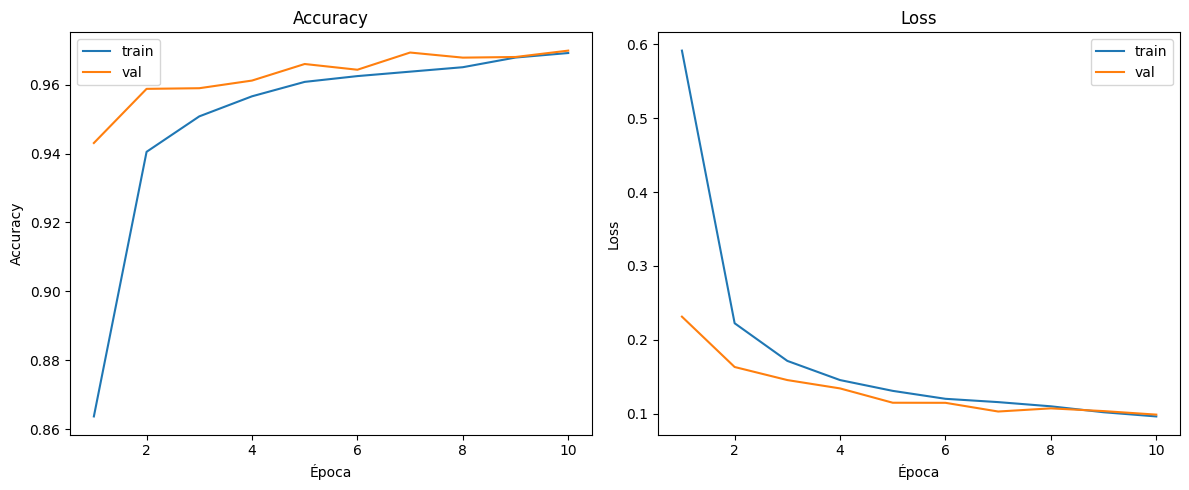

In [10]:
# 7. Curvas de entrenamiento
def plot_history(histories):
    acc, val_acc, loss, val_loss = [], [], [], []
    for hist in histories:
        acc.extend(hist.history.get('accuracy', []))
        val_acc.extend(hist.history.get('val_accuracy', []))
        loss.extend(hist.history.get('loss', []))
        val_loss.extend(hist.history.get('val_loss', []))
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='train')
    plt.plot(epochs_range, val_acc, label='val')
    plt.xlabel('Época'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Accuracy')
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='train')
    plt.plot(epochs_range, val_loss, label='val')
    plt.xlabel('Época'); plt.ylabel('Loss'); plt.legend(); plt.title('Loss')
    plt.tight_layout(); plt.show()

plot_history([history] + ([fine_tune_history] if RUN_FINE_TUNING else []))


In [11]:
# 8. Evaluación final en test y exportación
test_metrics = model.evaluate(test_ds, return_dict=True)
print('Métricas de test:', test_metrics)

final_path = MODEL_DIR / 'efficientnetb0_plantvillage.keras'
model.save(final_path)
np.save(MODEL_DIR / 'class_names.npy', np.array(class_names))
print('Modelo guardado en:', final_path)
print('Clases guardadas en:', MODEL_DIR / 'class_names.npy')


171/171 ━━━━━━━━━━━━━━━━━━━━ 55s 73ms/step - accuracy: 0.9669 - loss: 0.0969
Métricas de test: {'accuracy': 0.966917872428894, 'loss': 0.09686926752328873}
Modelo guardado en: /content/leafthealthvision/artifacts/efficientnetb0_plantvillage.keras
Clases guardadas en: /content/leafthealthvision/artifacts/class_names.npy


## Notas de reproducibilidad

- La configuración se concentra al inicio del notebook para facilitar experimentos en Colab.
- El split por lotes reproduce la línea base entregada, pero no garantiza separación por hoja física. Para resultados de investigación, usa los manifiestos `data/splits/{train,val,test}.csv` del EDA y documenta el hash de cada split.
- Reporta, además de accuracy, macro-F1, balanced accuracy, recall por clase y matriz de confusión.
- PlantVillage tiene condiciones controladas; la generalización a fotografías de campo requiere un conjunto externo.
